<a href="https://colab.research.google.com/github/prangyaparamita123/AML-LAB/blob/main/AMLlab3_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
dataset_path = '/content/cgpaPRED.xls'
try:
    df = pd.read_excel(dataset_path)
    print(f"Dataset '{dataset_path}' loaded successfully. Shape: {df.shape}")
    print("\nFirst 5 rows of the dataset:")
    print(df.head())
except FileNotFoundError:
    print(f"Error: The file '{dataset_path}' was not found. Please ensure it's uploaded correctly.")

    print("Creating a dummy dataset for demonstration purposes...")
    data = {
        'SEM 1': np.random.uniform(5.0, 9.0, 100),
        'SEM 2': np.random.uniform(5.0, 9.0, 100),
        'SEM 3': np.random.uniform(5.0, 9.0, 100),
        'SEM 4': np.random.uniform(5.0, 9.0, 100),
        'SEM 5': np.random.uniform(5.0, 9.0, 100)
    }
    df = pd.DataFrame(data)

    df['SEM 5'] = df['SEM 1'] * 0.3 + df['SEM 2'] * 0.2 + df['SEM 3'] * 0.2 + df['SEM 4'] * 0.3 + np.random.normal(0, 0.5, 100)
    df['SEM 5'] = df['SEM 5'].clip(5.0, 9.0)
    print("Dummy dataset created. First 5 rows:")
    print(df.head())
print("\n--- Exploratory Data Analysis (EDA) ---")
print("\nDataset Information:")
df.info()

print("\nDescriptive Statistics:")
print(df.describe())
print("\n--- Simple Linear Regression ---")

if 'SEM 1' in df.columns and 'SEM 5' in df.columns:
    X_slr = df[['SEM 1']]
    y_slr = df['SEM 5']
    X_train_slr, X_test_slr, y_train_slr, y_test_slr = train_test_split(X_slr, y_slr, test_size=0.2, random_state=42)
    slr_model = LinearRegression()
    slr_model.fit(X_train_slr, y_train_slr)
    y_pred_slr = slr_model.predict(X_test_slr)
    print(f"Coefficients (SEM 1): {slr_model.coef_[0]:.2f}")
    print(f"Intercept: {slr_model.intercept_:.2f}")
    print(f"Mean Squared Error: {mean_squared_error(y_test_slr, y_pred_slr):.2f}")
    print(f"R-squared: {r2_score(y_test_slr, y_pred_slr):.2f}")
else:
    print("Skipping Simple Linear Regression: 'SEM 1' or 'SEM 5' column not found in the dataset.")
print("\n--- Multiple Linear Regression ---")
independent_vars_mlr = ['SEM 1', 'SEM 2', 'SEM 3', 'SEM 4']
dependent_var_mlr = 'SEM 5'
if all(col in df.columns for col in independent_vars_mlr) and dependent_var_mlr in df.columns:
    X_mlr = df[independent_vars_mlr]
    y_mlr = df[dependent_var_mlr]

    X_train_mlr, X_test_mlr, y_train_mlr, y_test_mlr = train_test_split(X_mlr, y_mlr, test_size=0.2, random_state=42)

    mlr_model = LinearRegression()
    mlr_model.fit(X_train_mlr, y_train_mlr)

    y_pred_mlr = mlr_model.predict(X_test_mlr)

    print("Coefficients:")
    for i, col in enumerate(independent_vars_mlr):
        print(f"  {col}: {mlr_model.coef_[i]:.2f}")
    print(f"Intercept: {mlr_model.intercept_:.2f}")
    print(f"Mean Squared Error: {mean_squared_error(y_test_mlr, y_pred_mlr):.2f}")
    print(f"R-squared: {r2_score(y_test_mlr, y_pred_mlr):.2f}")
else:
    print(f"Skipping Multiple Linear Regression: One or more of the columns {independent_vars_mlr} or '{dependent_var_mlr}' not found in the dataset.")


Dataset '/content/cgpaPRED.xls' loaded successfully. Shape: (379, 5)

First 5 rows of the dataset:
   SEM 1  SEM 2  SEM 3  SEM 4  SEM 5
0   6.60   7.60   6.90   7.22   7.08
1   7.77   7.22   7.00   7.90   7.47
2   6.90   6.00   7.12   7.54   6.89
3   5.50   6.60   6.70   6.50   6.33
4   7.20   6.00   7.21   7.70   7.03

--- Exploratory Data Analysis (EDA) ---

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 379 entries, 0 to 378
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SEM 1   379 non-null    float64
 1   SEM 2   379 non-null    float64
 2   SEM 3   379 non-null    float64
 3   SEM 4   379 non-null    float64
 4   SEM 5   379 non-null    float64
dtypes: float64(5)
memory usage: 14.9 KB

Descriptive Statistics:
            SEM 1       SEM 2       SEM 3       SEM 4       SEM 5
count  379.000000  379.000000  379.000000  379.000000  379.000000
mean     5.908707    6.015858    6.103852    6.167546  

Error: The file '/content/cgpaPRED.xls' was not found. Creating a dummy dataset for demonstration.
Dummy dataset created.


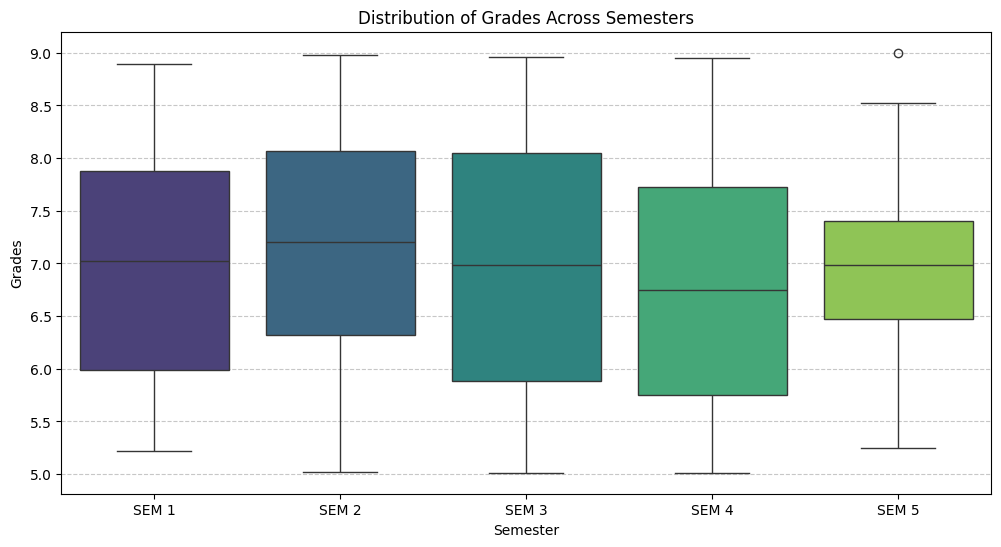

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

dataset_path = '/content/cgpaPRED.xls'
try:
    df = pd.read_excel(dataset_path)
    print(f"Dataset '{dataset_path}' loaded successfully. Shape: {df.shape}")
except FileNotFoundError:
    print(f"Error: The file '{dataset_path}' was not found. Creating a dummy dataset for demonstration.")
    data = {
        'SEM 1': np.random.uniform(5.0, 9.0, 100),
        'SEM 2': np.random.uniform(5.0, 9.0, 100),
        'SEM 3': np.random.uniform(5.0, 9.0, 100),
        'SEM 4': np.random.uniform(5.0, 9.0, 100),
        'SEM 5': np.random.uniform(5.0, 9.0, 100)
    }
    df = pd.DataFrame(data)
    df['SEM 5'] = df['SEM 1'] * 0.3 + df['SEM 2'] * 0.2 + df['SEM 3'] * 0.2 + df['SEM 4'] * 0.3 + np.random.normal(0, 0.5, 100)
    df['SEM 5'] = df['SEM 5'].clip(5.0, 9.0)
    print("Dummy dataset created.")

sem_columns = ['SEM 1', 'SEM 2', 'SEM 3', 'SEM 4', 'SEM 5']

if all(col in df.columns for col in sem_columns):
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=df[sem_columns], palette='viridis')
    plt.title('Distribution of Grades Across Semesters')
    plt.xlabel('Semester')
    plt.ylabel('Grades')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()
else:
    print(f"One or more of the specified SEM columns ({sem_columns}) not found in the DataFrame. Cannot generate boxplots.")

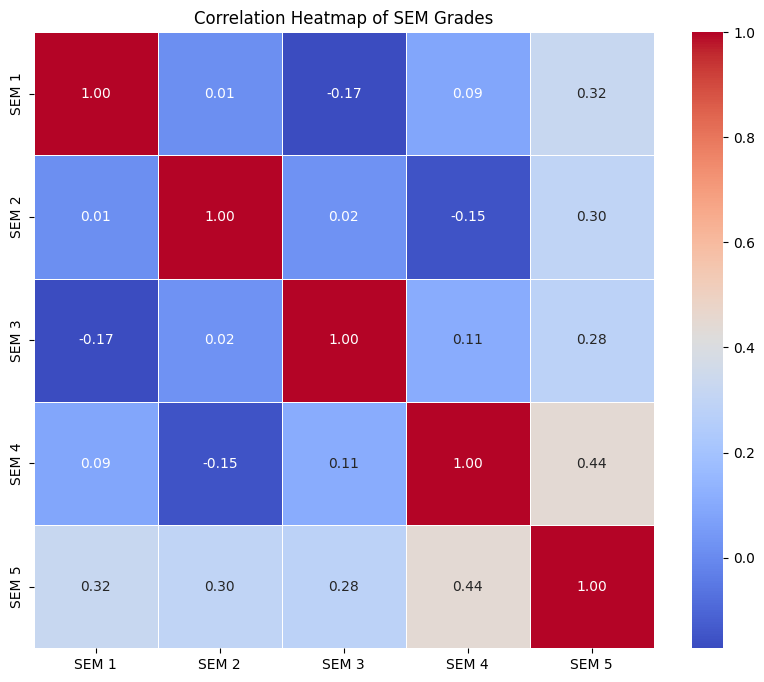

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sem_columns = ['SEM 1', 'SEM 2', 'SEM 3', 'SEM 4', 'SEM 5']

if all(col in df.columns for col in sem_columns):
    correlation_matrix = df[sem_columns].corr()

    plt.figure(figsize=(10, 8))
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
    plt.title('Correlation Heatmap of SEM Grades')
    plt.show()
else:
    print(f"One or more of the specified SEM columns ({sem_columns}) not found in the DataFrame. Cannot generate correlation heatmap.")